In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 04 · Variables — cada idea es una hipótesis que se mide

Crear variables es fácil; saber si **sirven** es lo difícil. Cada idea se mide con **los mismos modelos de
parámetros fijos, los mismos pliegues y las mismas métricas**; solo cambia el conjunto de variables. Una idea entra
solo si su mejora **supera la variación entre pliegues** (el ruido).

Qué produce este notebook:

- la **tabla de ideas medidas** con su decisión (`reports/04_features.md`),
- la **lista final de variables** que usará el torneo (`reports/04_seleccion_variables.json`),
- los **pliegues de validación**, que el notebook 05 reutiliza sin cambiar.

El código vive en `src/proyecto/features/engineering.py` (variables y preprocesamiento) y
`src/proyecto/models/train.py` (pipeline y evaluación). Este notebook **solo orquesta**.

## 0. Cargar los datos de entrenamiento

Solo el entrenamiento que dejó el notebook 03. **La prueba no se abre** hasta la validación final.

In [2]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

from proyecto.config import FEATURES, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, TARGET
from proyecto.data.split import make_folds
from proyecto.features.engineering import ENGINEERED_FEATURES, SUSPECT_COLUMNS, SUSPECT_ENGINEERED
from proyecto.models.train import build_pipeline, evaluate_folds, improvement_over_noise, paired_comparison
from proyecto.viz import ALERT, CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, TEXT, decimal_axis, fmt_num, set_style, table, titled

set_style()
pd.set_option("display.width", 160)

train = joblib.load(PROCESSED_DIR / "train.joblib")
print(f"Entrenamiento: {fmt_num(len(train))} asociados · tasa de radicación {fmt_num(train[TARGET].mean(), 3)} · la prueba sigue cerrada")
print(f"Variables actuales (referencia): {len(FEATURES)} = 21 originales + 3 indicadores de tenencia de producto")

Entrenamiento: 155.258 asociados · tasa de radicación 0,209 · la prueba sigue cerrada
Variables actuales (referencia): 24 = 21 originales + 3 indicadores de tenencia de producto


## 1. Las ideas, antes de medirlas

Cada idea sale de un hallazgo del EDA (notebook 02). Se escribe **qué es**, **por qué podría ayudar** y **si se conoce
al momento de decidir** a quién contactar.

| # | Idea | Cómo se calcula | Por qué podría ayudar (EDA) | ¿Se conoce al decidir? |
|---|---|---|---|---|
| 1 | `in_risk_window` | 1 si la antigüedad está entre 7 y 24 meses | Ahí la radicación supera el 30 % | Sí |
| 2 | `is_dormant` | 1 si no tiene aportes o no transacciona | El asociado "dormido" casi no radica | Sí |
| 3 | `n_products` | crédito + ahorro programado + cuenta (0 a 3) | Profundidad del vínculo | Sí |
| 4 | `savings_to_contributions` | (ahorro programado + cuenta) / aportes | Cuánto de su dinero está fuera de los aportes | Sí |
| 5 | `contributions_to_income` | aportes / ingresos | Peso de los aportes frente al ingreso | Sí (el ingreso es sospechoso) |
| 6 | `account_balance_trend` | saldo actual de la cuenta / saldo promedio | ¿Está vaciando la cuenta? | Sí, pero hereda la sospecha del saldo actual |
| 7 | `prog_savings_trend` | saldo actual de ahorro programado / promedio | Igual, para ahorro programado y CDT | Igual que la 6 |

Y cinco preguntas pendientes del EDA, que se responden con el mismo experimento:

| # | Pregunta | Variante que se mide |
|---|---|---|
| 8 | ¿Sirve el logaritmo en las colas largas? (decisión 10 del EDA) | referencia sin logaritmo |
| 9 | ¿Sobra una de cada pareja redundante? (decisión 12) | sin `prom_asesorias_publiturno` ni `prom_saldo_capitalizacion_aportes` |
| 10 | ¿Sobran las 8 variables que solas casi no separan? (sección 5 del EDA) | sin las 8 débiles |
| 11 | ¿Cuánto depende el modelo de las sospechas de fuga? (decisión 8) | sin `porc_meses_publiturno`, `prom_asesorias_publiturno`, `rel_min-max_saldo_cartera` ni `ingresos` |
| 12 | ¿Conviene entrenar sin los retiros unilaterales? (decisión 5) | entrenar sin ellos, evaluar con todos |

**Regla de decisión (escrita antes de medir).** Se mide con **dos modelos de parámetros fijos**: la **regresión
logística** (el modelo lineal, sensible a cómo se presentan las variables) y un **boosting de árboles**
(`HistGradientBoostingClassifier`, rápido, representante de los modelos de árboles del torneo). La métrica de decisión
es el **PR-AUC**; el beneficio neto se mira como control.

- **Agregar** una variable: se conserva si su **mejora / ruido > 1 en al menos uno de los dos modelos** y **no empeora
  al otro más allá del ruido** (mejora / ruido > −1), y si se conoce al decidir.
- **Quitar** variables (parsimonia): se quitan si la pérdida **queda dentro del ruido en los dos modelos**
  (mejora / ruido > −1 en ambos).
- **Sospechas de fuga y población:** el número dice **cuánto pesa** la decisión; la decisión se toma con el
  conocimiento del negocio (lo confirmado por el equipo) y queda escrita.

## 2. Validación común

Los pliegues se calculan **una sola vez** y se reutilizan en toda comparación de este notebook y en el torneo. Son
**por asociado** (`associate_id`) y estratificados por grupo (radicó / sigue activo / salió sin radicar), igual que la
partición del notebook 03.

In [3]:
folds = make_folds(train, n_splits=5, seed=RANDOM_STATE)
joblib.dump(folds, PROCESSED_DIR / "folds.joblib")

rows = []
for i, (fit_idx, valid_idx) in enumerate(folds):
    valid = train.iloc[valid_idx]
    rows.append({"pliegue": i, "asociados de ajuste": len(fit_idx), "asociados de validación": len(valid_idx),
                 "tasa de radicación (validación)": valid[TARGET].mean(),
                 "asociados en ambos lados": len(set(train.iloc[fit_idx]["associate_id"]) & set(valid["associate_id"]))})
display(table(pd.DataFrame(rows).set_index("pliegue"), decimals=3))
print("5 pliegues, guardados en data/processed/folds.joblib: los MISMOS para todo lo que se compare.")

,asociados de ajuste,asociados de validación,tasa de radicación (validación),asociados en ambos lados
pliegue,,,,
0,124.206,31.052,"0,209",0
1,124.207,31.051,"0,209",0
2,124.206,31.052,"0,209",0
3,124.207,31.051,"0,209",0
4,124.206,31.052,"0,209",0


5 pliegues, guardados en data/processed/folds.joblib: los MISMOS para todo lo que se compare.


## 3. El experimento

Dos modelos fijos, una variante por idea. Todos los pipelines aplican el mismo preprocesamiento (imputación con la
mediana, logaritmo en colas largas y escalado), ajustado **solo con la parte de ajuste de cada pliegue**.

In [4]:
reference = list(FEATURES)
redundant = ["prom_asesorias_publiturno", "prom_saldo_capitalizacion_aportes"]
weak = ["prom_saldo_ahorro_prog", "rel_min-max_saldo_cta", "asalariado", "ed_superior", "femenino", "edad",
        "zona_med", "prom_saldo_cta"]

variants = {"0 · referencia": dict(columns=reference)}
for i, name in enumerate(ENGINEERED_FEATURES, start=1):
    variants[f"{i} · + {name}"] = dict(columns=reference + [name])
variants["8 · sin logaritmo"] = dict(columns=reference, log_transform=False)
variants["9 · sin redundantes"] = dict(columns=[c for c in reference if c not in redundant])
variants["10 · sin las 8 débiles"] = dict(columns=[c for c in reference if c not in weak])
variants["11 · sin sospechas de fuga"] = dict(columns=[c for c in reference if c not in SUSPECT_COLUMNS])
variants["12 · sin retiros unilaterales (entrenamiento)"] = dict(columns=reference, train_mask=train["exit_without_request"] == 0)

fixed_models = {
    "regresión logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "boosting de árboles": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = {}
for model_name, model in fixed_models.items():
    for variant_name, options in variants.items():
        options = dict(options)
        mask = options.pop("train_mask", None)
        results[(model_name, variant_name)] = evaluate_folds(build_pipeline(model, **options), train, folds, train_mask=mask)
    print(f"{model_name}: {len(variants)} variantes × 5 pliegues listas")

regresión logística: 13 variantes × 5 pliegues listas


boosting de árboles: 13 variantes × 5 pliegues listas


## 4. Mejora sobre ruido

Para cada variante: el PR-AUC medio, su desviación entre pliegues (el **ruido**), la mejora frente a la referencia,
**mejora / ruido** y en cuántos pliegues gana (comparación pareada). El beneficio neto por cada 1.000 asociados
(millones de COP, supuestos del notebook 01) acompaña como control.

In [5]:
def idea_table(model_name):
    ref = results[(model_name, "0 · referencia")]
    rows = []
    for variant_name in variants:
        res = results[(model_name, variant_name)]
        ap = improvement_over_noise(ref["PR-AUC"], res["PR-AUC"])
        money = improvement_over_noise(ref["beneficio neto (por 1.000)"], res["beneficio neto (por 1.000)"])
        rows.append({"variante": variant_name, "PR-AUC": res["PR-AUC"].mean(), "± ruido": res["PR-AUC"].std(),
                     "mejora": ap["mejora"], "mejora / ruido": ap["mejora / ruido"],
                     "pliegues que gana": paired_comparison(res["PR-AUC"], ref["PR-AUC"])["pliegues que gana"],
                     "beneficio neto (por 1.000)": res["beneficio neto (por 1.000)"].mean(),
                     "beneficio: mejora / ruido": money["mejora / ruido"]})
    return pd.DataFrame(rows).set_index("variante")

tables = {name: idea_table(name) for name in fixed_models}
for name, t in tables.items():
    print(f"\n{name.upper()}")
    display(table(t, decimals=4, col_decimals={"mejora / ruido": 2, "beneficio: mejora / ruido": 2,
                                               "beneficio neto (por 1.000)": 2}))


REGRESIÓN LOGÍSTICA


,PR-AUC,± ruido,mejora,mejora / ruido,pliegues que gana,beneficio neto (por 1.000),beneficio: mejora / ruido
variante,,,,,,,
0 · referencia,"0,4722","0,0042","0,0000","0,00",0 de 5,"31,79","0,00"
1 · + in_risk_window,"0,4910","0,0045","0,0188","4,21",5 de 5,"31,74","-0,08"
2 · + is_dormant,"0,4923","0,0034","0,0200","5,82",5 de 5,"32,02","0,35"
3 · + n_products,"0,4722","0,0042","-0,0000","-0,01",1 de 5,"31,79","-0,00"
4 · + savings_to_contributions,"0,5024","0,0042","0,0301","7,22",5 de 5,"32,20","0,63"
5 · + contributions_to_income,"0,4722","0,0042","-0,0000","-0,01",1 de 5,"31,79","0,00"
6 · + account_balance_trend,"0,4764","0,0038","0,0041","1,08",5 de 5,"31,81","0,03"
7 · + prog_savings_trend,"0,4780","0,0051","0,0057","1,13",5 de 5,"31,88","0,12"
8 · sin logaritmo,"0,4546","0,0041","-0,0177","-4,30",0 de 5,"31,73","-0,09"



BOOSTING DE ÁRBOLES


,PR-AUC,± ruido,mejora,mejora / ruido,pliegues que gana,beneficio neto (por 1.000),beneficio: mejora / ruido
variante,,,,,,,
0 · referencia,"0,7167","0,0064","0,0000","0,00",0 de 5,"33,98","0,00"
1 · + in_risk_window,"0,7165","0,0068","-0,0002","-0,02",2 de 5,"33,98","-0,00"
2 · + is_dormant,"0,7167","0,0064","0,0000","0,00",0 de 5,"33,98","0,00"
3 · + n_products,"0,7169","0,0076","0,0002","0,03",4 de 5,"34,01","0,05"
4 · + savings_to_contributions,"0,7169","0,0063","0,0002","0,04",3 de 5,"34,01","0,05"
5 · + contributions_to_income,"0,7167","0,0062","0,0000","0,01",3 de 5,"34,02","0,06"
6 · + account_balance_trend,"0,7168","0,0060","0,0001","0,02",3 de 5,"34,01","0,05"
7 · + prog_savings_trend,"0,7166","0,0062","-0,0000","-0,00",3 de 5,"33,94","-0,06"
8 · sin logaritmo,"0,7166","0,0065","-0,0001","-0,01",3 de 5,"33,93","-0,08"


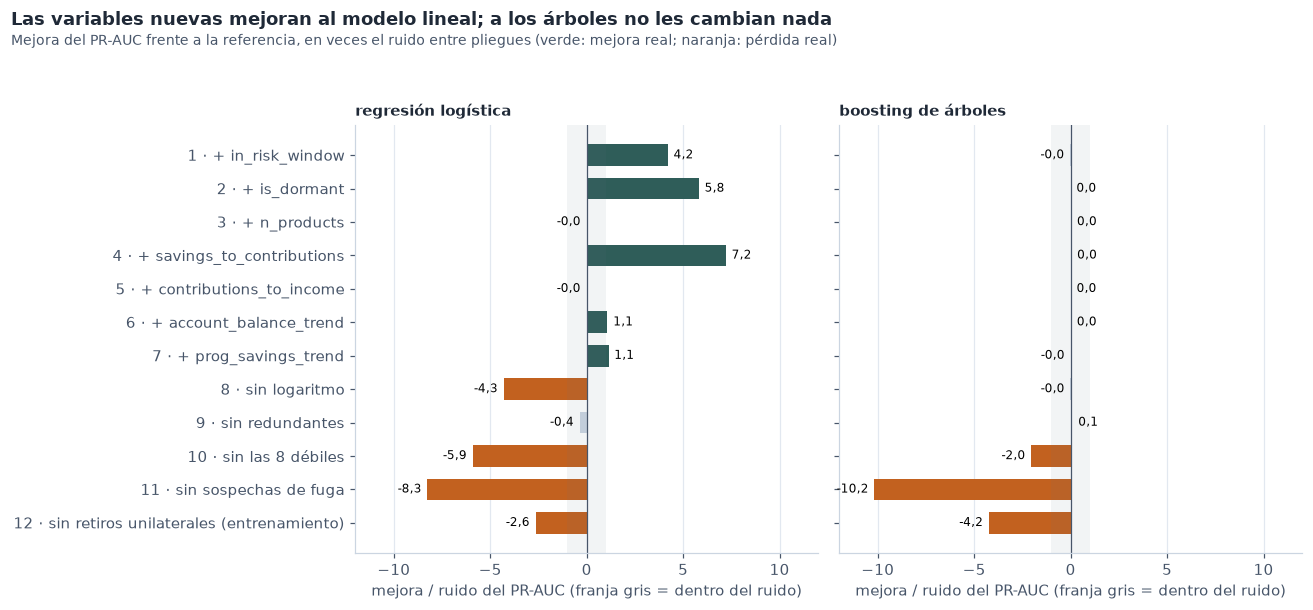

In [6]:
order = list(variants)[1:]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    ratio = t.loc[order, "mejora / ruido"].clip(-12, 12)
    colors = [STAY if r > 1 else (CHURN if r < -1 else LIGHT) for r in ratio]
    ax.barh(order, ratio, color=colors, height=0.65)
    ax.axvspan(-1, 1, color=NEUTRAL, alpha=0.08, lw=0)
    ax.axvline(0, color=SUBTEXT, lw=0.8)
    for y, r in enumerate(ratio):
        ax.text(r + (0.3 if r >= 0 else -0.3), y, fmt_num(r, 1), va="center", ha="left" if r >= 0 else "right", fontsize=8)
    ax.set_xlim(-12, 12)
    ax.set_xlabel("mejora / ruido del PR-AUC (franja gris = dentro del ruido)")
    ax.grid(axis="y", visible=False)
    ax.set_title(name, loc="left", fontsize=10, color=TEXT)
axes[0].invert_yaxis()
fig.suptitle("Las variables nuevas mejoran al modelo lineal; a los árboles no les cambian nada",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold", color=TEXT)
fig.text(0.01, 0.925, "Mejora del PR-AUC frente a la referencia, en veces el ruido entre pliegues (verde: mejora real; "
         "naranja: pérdida real)", fontsize=9, color=SUBTEXT, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()

**Lectura.**

- **En la regresión logística**, cinco de las siete ideas superan el ruido y ganan en los 5 pliegues. Las más fuertes
  son `savings_to_contributions`, `is_dormant` e `in_risk_window`. Las dos tendencias de saldo (`account_balance_trend`,
  `prog_savings_trend`) apenas pasan el umbral de 1.
- **En el boosting de árboles ninguna idea mueve el PR-AUC fuera del ruido**: los árboles ya encuentran solos los
  cortes (la ventana de antigüedad, el asociado sin movimiento) y las interacciones que las variables nuevas le dan
  "masticadas" al modelo lineal.
- **`n_products` y `contributions_to_income` no aportan en ninguno.** `n_products` es la suma de los tres indicadores
  de tenencia que ya están en la referencia, así que no le dice nada nuevo al modelo lineal.
- **El logaritmo sí importa para la logística** (quitarlo es una pérdida real) y a los árboles les es indiferente:
  se confirma la decisión 10 del EDA.
- **Quitar una de cada pareja redundante no cuesta nada** en ninguno de los dos modelos (dentro del ruido).
- **Las 8 variables débiles sí aportan combinadas**: quitarlas es una pérdida real en los dos modelos.
- **El salto entre modelos es mucho mayor que cualquier variable**: el boosting de árboles tiene un PR-AUC muy por
  encima de la logística en cualquier variante (tablas). Lo que más pesa en este problema es la forma del modelo, y
  eso lo decide el torneo.

## 5. Sospechas de fuga y población de entrenamiento

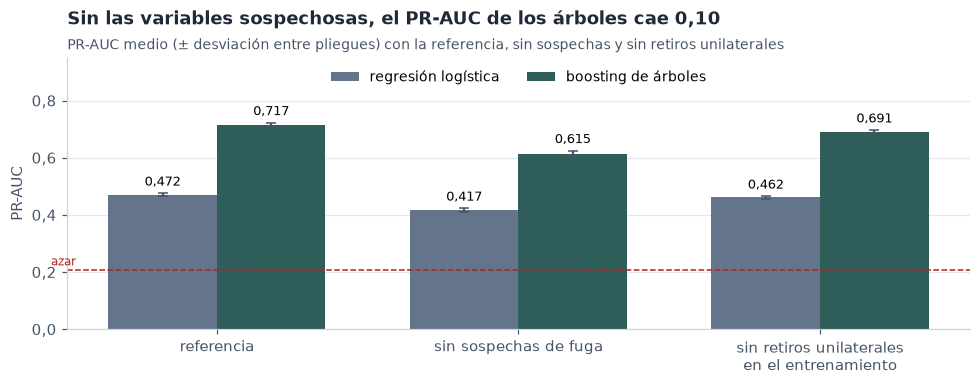

In [7]:
checks = ["0 · referencia", "11 · sin sospechas de fuga", "12 · sin retiros unilaterales (entrenamiento)"]
labels = ["referencia", "sin sospechas de fuga", "sin retiros unilaterales\nen el entrenamiento"]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(checks)); width = 0.36
for i, (name, color) in enumerate(zip(fixed_models, [NEUTRAL, STAY])):
    means = [results[(name, c)]["PR-AUC"].mean() for c in checks]
    stds = [results[(name, c)]["PR-AUC"].std() for c in checks]
    bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, color=color, label=name,
                  error_kw={"ecolor": SUBTEXT, "capsize": 3})
    ax.bar_label(bars, labels=[fmt_num(v, 3) for v in means], padding=3, fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 0.95); ax.set_ylabel("PR-AUC")
ax.axhline(train[TARGET].mean(), color=ALERT, ls="--", lw=1)
ax.text(-0.55, train[TARGET].mean() + 0.015, "azar", color=ALERT, fontsize=8)
ax.legend(loc="upper center", ncol=2); ax.grid(axis="x", visible=False); decimal_axis(ax, "y")
drop = results[("boosting de árboles", checks[0])]["PR-AUC"].mean() - results[("boosting de árboles", checks[1])]["PR-AUC"].mean()
titled(ax, f"Sin las variables sospechosas, el PR-AUC de los árboles cae {fmt_num(drop, 2)}",
       "PR-AUC medio (± desviación entre pliegues) con la referencia, sin sospechas y sin retiros unilaterales")
plt.tight_layout(); plt.show()

**Lectura y decisión.**

- **El modelo depende mucho de las cuatro variables sospechosas** (visitas y asesorías en sucursal, cartera mínima en
  cero, ingreso): sin ellas, el PR-AUC cae en los dos modelos, muchas veces más que el ruido (tablas de la sección 4).
  Si fueran fuga, buena parte del desempeño sería falso.
- **El equipo confirmó (31-oct-2026) que las variables no incluyen el mes de radicación.** Con eso, **se conservan**,
  con tres condiciones escritas: (1) el torneo reporta también a los finalistas **sin** ellas, para saber cuánto vale
  el modelo en el peor caso; (2) queda por aclarar por qué los porcentajes de meses dividen por antigüedad + 1
  (notebook 02); (3) el piloto con grupo de control es la prueba definitiva.
- **Retiros unilaterales:** entrenar sin ellos **empeora** el PR-AUC en los dos modelos (evaluado sobre todos los
  asociados de validación, como será en producción, donde no se sabe a quién terminará la cooperativa). Le enseñan al
  modelo cómo es un perfil que no radica. **Se conservan en el entrenamiento** con `sol_retiro = 0`.

## 6. La selección final, medida

Se aplican las decisiones y se mide la lista final con los mismos pliegues, para confirmar que la combinación se
comporta como sus partes.

In [8]:
keep_new = [n for n in ENGINEERED_FEATURES
            if max(tables[m].loc[f"{ENGINEERED_FEATURES.index(n) + 1} · + {n}", "mejora / ruido"] for m in tables) > 1
            and min(tables[m].loc[f"{ENGINEERED_FEATURES.index(n) + 1} · + {n}", "mejora / ruido"] for m in tables) > -1]
drop_redundant = all(tables[m].loc["9 · sin redundantes", "mejora / ruido"] > -1 for m in tables)
final_columns = [c for c in reference if not (drop_redundant and c in redundant)] + keep_new
print("Variables nuevas que cumplen la regla:", keep_new)
print("¿Se quitan las redundantes?", drop_redundant, "->", redundant if drop_redundant else "no")
print(f"Lista final: {len(final_columns)} variables")

final_rows = []
for name, model in fixed_models.items():
    res = evaluate_folds(build_pipeline(model, columns=final_columns), train, folds)
    results[(name, "selección final")] = res
    ref = results[(name, "0 · referencia")]
    gain = improvement_over_noise(ref["PR-AUC"], res["PR-AUC"])
    final_rows.append({"modelo": name, "PR-AUC referencia": ref["PR-AUC"].mean(), "PR-AUC selección final": res["PR-AUC"].mean(),
                       "± ruido": res["PR-AUC"].std(), "mejora / ruido": gain["mejora / ruido"],
                       "pliegues que gana": paired_comparison(res["PR-AUC"], ref["PR-AUC"])["pliegues que gana"],
                       "AUC selección final": res["AUC"].mean(),
                       "beneficio neto (por 1.000)": res["beneficio neto (por 1.000)"].mean()})
final_table = pd.DataFrame(final_rows).set_index("modelo")
display(table(final_table, decimals=4, col_decimals={"mejora / ruido": 2, "beneficio neto (por 1.000)": 2}))

Variables nuevas que cumplen la regla: ['in_risk_window', 'is_dormant', 'savings_to_contributions', 'account_balance_trend', 'prog_savings_trend']
¿Se quitan las redundantes? True -> ['prom_asesorias_publiturno', 'prom_saldo_capitalizacion_aportes']
Lista final: 27 variables


,PR-AUC referencia,PR-AUC selección final,± ruido,mejora / ruido,pliegues que gana,AUC selección final,beneficio neto (por 1.000)
modelo,,,,,,,
regresión logística,"0,4722","0,5145","0,0047","8,92",5 de 5,"0,8189","32,17"
boosting de árboles,"0,7167","0,7170","0,0065","0,05",2 de 5,"0,9006","33,99"


In [9]:
selection = {
    "columns": final_columns,
    "engineered_kept": keep_new,
    "engineered_discarded": [n for n in ENGINEERED_FEATURES if n not in keep_new],
    "dropped_redundant": redundant if drop_redundant else [],
    "log_transform": True,
    "scale": True,
    "train_without_unilateral_exits": False,
    "leakage_suspects_kept": [c for c in SUSPECT_COLUMNS if c in final_columns]
                             + [c for c in SUSPECT_ENGINEERED if c in final_columns],
}
(REPORTS_DIR / "04_seleccion_variables.json").write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding="utf-8")
pd.concat({f"{m} | {v}": t for (m, v), t in results.items()}).to_csv(REPORTS_DIR / "04_features_pliegues.csv")
print("Guardado: reports/04_seleccion_variables.json (lo lee el torneo) y reports/04_features_pliegues.csv (cada pliegue)")
print("Sospechas que siguen en el modelo:", selection["leakage_suspects_kept"])

Guardado: reports/04_seleccion_variables.json (lo lee el torneo) y reports/04_features_pliegues.csv (cada pliegue)
Sospechas que siguen en el modelo: ['porc_meses_publiturno', 'rel_min-max_saldo_cartera', 'ingresos', 'account_balance_trend', 'prog_savings_trend']


**Lectura.** La selección final mejora a la regresión logística muy por encima del ruido y deja al boosting de árboles
donde estaba (tabla). Es lo esperado: las variables nuevas son "atajos" que el modelo lineal necesita y que los árboles
construyen solos. Como no le quitan nada a ningún modelo y se calculan fila por fila con datos que se conocen al
decidir, el torneo usa esta lista **para todos los candidatos**, y así ninguno compite en condiciones distintas.

## 7. Decisiones

| # | Idea | Mejora / ruido (logística · árboles) | Decisión | Motivo |
|---|---|---|---|---|
| 1 | `in_risk_window` | 4,21 · −0,02 | conservar | Mejora real en la logística (5 de 5 pliegues); neutra en árboles |
| 2 | `is_dormant` | 5,82 · 0,00 | conservar | Mejora real en la logística (5 de 5); neutra en árboles |
| 3 | `n_products` | −0,01 · 0,03 | **descartar** | Dentro del ruido en ambos: es la suma de indicadores que ya están |
| 4 | `savings_to_contributions` | 7,22 · 0,04 | conservar | La mejora más grande en la logística (5 de 5) |
| 5 | `contributions_to_income` | −0,01 · 0,01 | **descartar** | Dentro del ruido en ambos; además depende del ingreso (sospechoso) |
| 6 | `account_balance_trend` | 1,08 · 0,02 | conservar, **vigilada** | Pasa la regla por poco; hereda la sospecha del saldo "al momento de la solicitud" |
| 7 | `prog_savings_trend` | 1,13 · −0,00 | conservar, **vigilada** | Igual que la 6 |
| 8 | logaritmo en colas largas | −4,30 · −0,01 (quitarlo) | conservar | Quitarlo es una pérdida real en la logística |
| 9 | una de cada pareja redundante | −0,36 · 0,10 (quitarlas) | **quitar** `prom_asesorias_publiturno` y `prom_saldo_capitalizacion_aportes` | Pérdida dentro del ruido en ambos: parsimonia |
| 10 | 8 variables débiles | −5,91 · −2,04 (quitarlas) | conservar | Quitarlas es una pérdida real en ambos |
| 11 | sospechas de fuga | −8,26 · −10,17 (quitarlas) | conservar, **con condiciones** | Confirmación del equipo; el torneo mide a los mejores sin ellas |
| 12 | retiros unilaterales | −2,65 · −4,23 (sacarlos) | **conservar en el entrenamiento** | Sacarlos empeora el modelo en ambos |

Mejora / ruido del PR-AUC: primero la regresión logística, después el boosting de árboles (tablas de la sección 4).

> **Dos de siete ideas no sirvieron, y eso es información.** Igual que en el ejemplo del curso, la mayor diferencia
> no vino de inventar columnas sino de **cómo es el modelo**: eso lo decide el torneo (notebook 05).

## Entregable de esta etapa

- [x] Cada idea tiene su fila con **mejora / ruido** y una decisión escrita.
- [x] Todas las variantes se midieron con **los mismos pliegues**, por asociado.
- [x] Ninguna variable usa información que no se conoce al decidir (las heredadas de sospechas, marcadas).
- [x] El código reutilizable está en `src/proyecto/features/` y `src/proyecto/models/`; este notebook solo lo llama.
- [x] `reports/04_features.md` completado y la lista final en `reports/04_seleccion_variables.json`.

**Siguiente:** `05_torneo.ipynb`.